# Exercise 1
The file 'employees.csv' contains data of employees of a certain small company. The names of the employees and of the company were omitted to assure data privacy. In this exercise, we will:
- Open/visualize the data
- Spot errors/problems and clean the data
- Convert one of the categorical variables ('Highest degree') to numbers
- Split the data into training and test set

### Import the needed libraries/modules/functions

In [26]:
# If you are inside a local jupyter notebook session, uncomment the line below (remove "#") and run it
#!pip install scikit-learn pandas matplotlib

# If you are in anaconda prompt powershell or in a terminal (windows, Linux or mac), use the command below (without "#")
# conda install scikit-learn pandas matplotlib

In [27]:
import pandas as pd # Main library to manipulate the data
from sklearn.model_selection import train_test_split # Split the data

### Part 1 - Open/visualize the data

In [28]:
data = pd.read_csv('employees.csv') # load the csv file as a DataFrame object named 'data'
data # check the object 'data'

,Age,Experience / years,Highest degree,Salary
0,60.0,3,school,50525.89
1,35.0,7,bachelor,48784.13
2,54.0,2,PhD,89986.33
3,21.0,2,bachelor,25521.71
4,52.0,19,school,51360.49
5,54.0,13,bachelor,65458.17
6,57.0,8,school,52860.54
7,47.0,10,master,75749.97
8,33.0,10,school,31411.39
9,44.0,3,master,63234.23


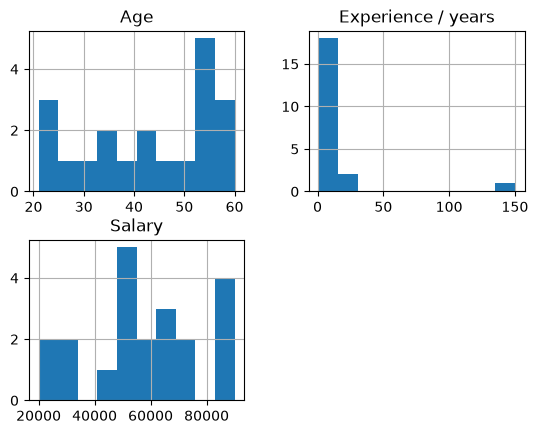

In [29]:
# Let's check the histograms
# Why the "Highest degree" did not appeared below?? We will come to this later...
data.hist(); # plot histograms for all numeric columns of the object 'data'. Note: ";" avoids showing unwanted messages

In [30]:
# get statistics on the columns:
# Why the column "Highest degree" is not shown??
data.describe()

,Age,Experience / years,Salary
count,20.000000,21.000000,21.000000
mean,43.050000,15.428571,58099.374762
std,13.248535,31.296280,20532.529236
min,21.000000,1.000000,19968.890000
25%,32.250000,3.000000,48784.130000
50%,45.500000,9.000000,58323.110000
75%,54.000000,13.000000,74480.440000
max,60.000000,150.000000,89986.330000


### Part 2: Spot errors/problems and clean the data
Try to find the following problems in your data: a) Duplicated rows, b) Error or outlier; c) Missing values (represented 'NaN': Not a Number)

#### 2.1: duplicates

In [31]:
data.shape # how many rows and columns? The output shows (# rows, # cols)

(21, 4)

In [32]:
data = data.drop_duplicates() # which row was removed?? check missing indices in the index column!
data

,Age,Experience / years,Highest degree,Salary
0,60.0,3,school,50525.89
1,35.0,7,bachelor,48784.13
2,54.0,2,PhD,89986.33
3,21.0,2,bachelor,25521.71
4,52.0,19,school,51360.49
5,54.0,13,bachelor,65458.17
6,57.0,8,school,52860.54
7,47.0,10,master,75749.97
8,33.0,10,school,31411.39
9,44.0,3,master,63234.23


In [33]:
data.shape # new dataset size. We have fewer rows now because 1 duplicate was removed!

(20, 4)

#### 2.2) missing values (NaN)

In [34]:
data.isna().sum() # How many missing values per column?

Age                   1
Experience / years    0
Highest degree        0
Salary                0
dtype: int64

In [35]:
data['Age'].mean() # What is the average value in the "Age" column? This will be used in the next cell...

np.float64(42.473684210526315)

In [36]:
data.loc[20,'Age'] = 42 # element at row of index ID 20 and column "Age" should be 42 (replace NaN by the average)
# Note: we could replace ALL missing (NaN) values at the same time (e.g. via data['Age'].fillna(42)), 
#         but let's keep it simple for now...)

In [37]:
data # check the dataframe again

,Age,Experience / years,Highest degree,Salary
0,60.0,3,school,50525.89
1,35.0,7,bachelor,48784.13
2,54.0,2,PhD,89986.33
3,21.0,2,bachelor,25521.71
4,52.0,19,school,51360.49
5,54.0,13,bachelor,65458.17
6,57.0,8,school,52860.54
7,47.0,10,master,75749.97
8,33.0,10,school,31411.39
9,44.0,3,master,63234.23


#### 2.3) Are there outlier/errors?

<Axes: >

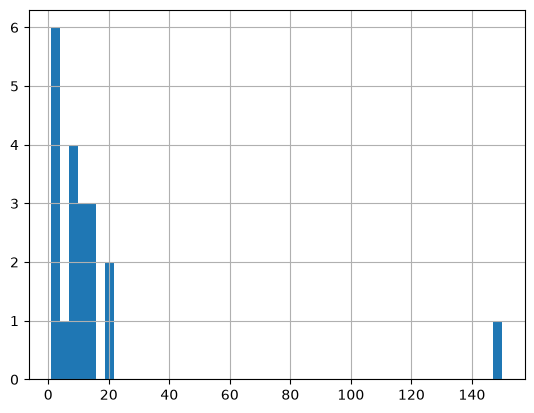

In [38]:
data['Experience / years'].hist(bins=50) # see (again!) a histogram with the values of the "Experimence / Years" column
# it seems that one single person has > 140 years or experience (fake news??)

In [39]:
data['Experience / years'] <= 80 # this is amask

0      True
1      True
2      True
3      True
4      True
5      True
6      True
7      True
8      True
9      True
10    False
11     True
12     True
13     True
14     True
15     True
16     True
17     True
18     True
20     True
Name: Experience / years, dtype: bool

In [40]:
# Apply a filter to only get 'Experience / years' values smaller than a reasonable threshold (e.g., 80 years)
data[ data['Experience / years'] <= 80 ]  # we did not redefine data, only visualized the filtered results

,Age,Experience / years,Highest degree,Salary
0,60.0,3,school,50525.89
1,35.0,7,bachelor,48784.13
2,54.0,2,PhD,89986.33
3,21.0,2,bachelor,25521.71
4,52.0,19,school,51360.49
5,54.0,13,bachelor,65458.17
6,57.0,8,school,52860.54
7,47.0,10,master,75749.97
8,33.0,10,school,31411.39
9,44.0,3,master,63234.23


In [41]:
data = data[ data['Experience / years'] <= 80 ] # apply the filtering AND redefine the data
data # check 'data'

,Age,Experience / years,Highest degree,Salary
0,60.0,3,school,50525.89
1,35.0,7,bachelor,48784.13
2,54.0,2,PhD,89986.33
3,21.0,2,bachelor,25521.71
4,52.0,19,school,51360.49
5,54.0,13,bachelor,65458.17
6,57.0,8,school,52860.54
7,47.0,10,master,75749.97
8,33.0,10,school,31411.39
9,44.0,3,master,63234.23


In [42]:
data.shape # Now we have 19 rows (or persons): we eliminated 1 outlier and 1 duplicate up to now...

(19, 4)

In [43]:
# Let's save a the current (clean) version of data:
data.to_csv('employees_clean.csv', index=False) # save the current 'data' DataFrame to the given csv file (without the index ID)

## 2) - Convert 'Highest degree' column from string to integer (encoding problem)
ML models require numbers only, not text!

In [44]:
data = pd.read_csv('employees_clean.csv')

In [47]:
mapping = {
    'school': 1,
    'bachelor': 2,
    'master': 3,
    'PhD': 4
}

data['Highest degree'] = (
    data['Highest degree'].map(mapping).astype('Int64')
)

In [ ]:
mapping = {'school':1, 'bachelor':2, 'master':3, 'PhD':4} # create a dictionary to convert strings to numbers

data.loc[:, 'Highest degree'] = data['Highest degree'].map(mapping) # replace this column with a modified one
# Note: The colon symbol ":" in the line above means "ALL" rows

TypeError: Invalid value '<IntegerArray>
[1, 2, 4, 2, 1, 2, 1, 3, 1, 3, 4, 3, 2, 1, 3, 2, 2, 4, 3]
Length: 19, dtype: Int64' for dtype 'str'

In [48]:
data # Now we have a CLEAN DataFrame object with numbers only :-)

,Age,Experience / years,Highest degree,Salary
0,60.0,3,1,50525.89
1,35.0,7,2,48784.13
2,54.0,2,4,89986.33
3,21.0,2,2,25521.71
4,52.0,19,1,51360.49
5,54.0,13,2,65458.17
6,57.0,8,1,52860.54
7,47.0,10,3,75749.97
8,33.0,10,1,31411.39
9,44.0,3,3,63234.23


In [49]:
# save the clean/encoded dataset for later
data.to_csv('employees_clean_encoded.csv', index=False) # save the current DataFrame to the provided csv file (without the index ID)

## 3) Split the dataset into training (80% of rows) and test (20% of rows) sets

In [50]:
X = data.drop(['Salary'], axis = 1) # Our features (or independent variables), usually called X
# axis = 1 means that we are talking about columns, not rows.

y = data['Salary'] # Our target property (what we want to predict), usually called y
# when DataFrame objects (like y above) have only 1 column, they are called Series

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # Use "help(train_test_split)" to learn more...
# Here, 20 % of the rows are randomly selected and saved as the test set (X_test, y_test), the remainder is the training set

In [51]:
X_train # Check the randomly selected rows of the training set. Notice the random index ID's!

,Age,Experience / years,Highest degree
8,33.0,10,1
16,24.0,19,2
3,21.0,2,2
13,25.0,7,1
15,43.0,11,2
17,30.0,14,4
2,54.0,2,4
9,44.0,3,3
18,42.0,6,3
4,52.0,19,1


In [52]:
y_train # Check the randomly selected rows of the training set (targets, corresponding to X_train above)

8     31411.39
16    43707.37
3     25521.71
13    19968.89
15    58323.11
17    74480.44
2     89986.33
9     63234.23
18    51690.42
4     51360.49
12    32477.62
7     75749.97
10    89584.38
14    61393.36
6     52860.54
Name: Salary, dtype: float64

In [53]:
X_test # Check the randomly selected rows of the test set. Notice the random index ID's!

,Age,Experience / years,Highest degree
0,60.0,3,1
5,54.0,13,2
11,55.0,9,3
1,35.0,7,2


In [54]:
y_test # Check the randomly selected rows of the test set (targets, corresponding to X_test above)

0     50525.89
5     65458.17
11    84949.74
1     48784.13
Name: Salary, dtype: float64

<Br><Br>
# Task
Split the dataset again using 5 different random states of your choice (instead of only 42 as used above). Each time, compute the mean of y_test (Does it change? Why?). Calculate the overall average and standard deviation of this mean for all five splittings.

In [62]:
# 5 random state

random_states = [1, 10, 15, 20, 50]
test_salary_means = []

for state in random_states:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=state
    )

    mean_salary = y_test.mean()
    test_salary_means.append(mean_salary)

    print(f"Random state {state}: mean salary = {mean_salary:.2f}")

overall_average = pd.Series(test_salary_means).mean()
overall_std = pd.Series(test_salary_means).std()

print('test_salary_means:', test_salary_means)

print("\nOverall average of mean salaries:", overall_average)
print("Standard deviation:", overall_std)

Random state 1: mean salary = 56572.44
Random state 10: mean salary = 60302.57
Random state 15: mean salary = 40103.81
Random state 20: mean salary = 61331.64
Random state 50: mean salary = 57629.86
test_salary_means: [np.float64(56572.435000000005), np.float64(60302.572499999995), np.float64(40103.8125), np.float64(61331.6425), np.float64(57629.855)]

Overall average of mean salaries: 55188.063500000004
Standard deviation: 8650.364495944772
